
--- Dataset Overview ---
  manufacturer    model   type drive_type fuel_type  color  battery_kwh  \
0          BYD  Model S  Coupe        FWD  Electric   Blue        84.93   
1        Lucid      EV6  Sedan        AWD  Electric   Blue        65.14   
2   Volkswagen      EV6    SUV        FWD    Hybrid  White        22.75   
3          BMW    Ioniq  Sedan        AWD    Hybrid  Black        71.72   
4   Volkswagen  Model 3  Truck        AWD    Hybrid  Green        62.99   

   range_km  charging_time_hr  fast_charging  ...       city seats price_usd  \
0    464.06              0.85           True  ...   Shanghai     7   32213.0   
1    345.36              2.03           True  ...      Tokyo     7   31125.0   
2    104.25              0.22           True  ...       Oslo     5   15674.0   
3    341.74              0.48          False  ...  Vancouver     2   24044.0   
4    338.16              0.79           True  ...   Shenzhen     4   29567.0   

   efficiency_score  acceleration_0_100_km

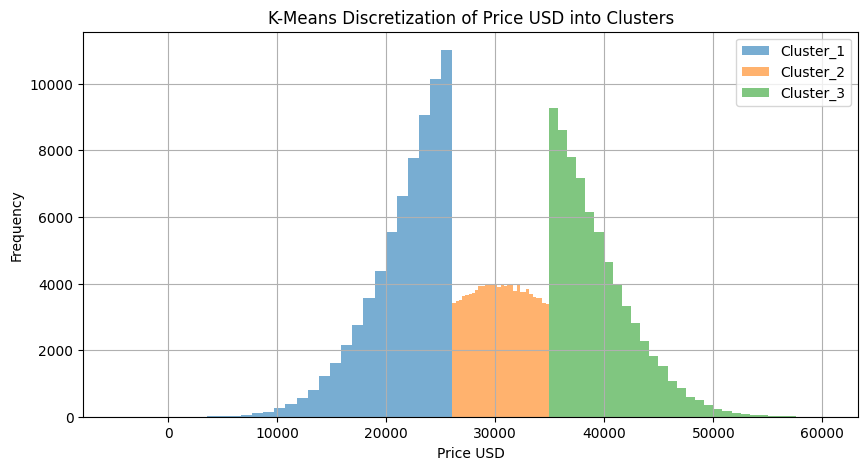

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Path to the existing dataset
file_path = '/content/EV_dataset.csv'
df = pd.read_csv(file_path)

print("\n--- Dataset Overview ---")
print(df.head())

target_col = 'price_usd'

print(f"\nOriginal Attribute Statistics for '{target_col}':")
print(f"Min  : {df[target_col].min()}")
print(f"Max  : {df[target_col].max()}")
print(f"Mean : {df[target_col].mean():.4f}")
print(f"Std  : {df[target_col].std():.4f}")

# 1. MIN-MAX NORMALIZATION
min_val = df[target_col].min()
max_val = df[target_col].max()
df['price_min_max'] = (df[target_col] - min_val) / (max_val - min_val)

# 2. Z-SCORE NORMALIZATION
mean_val = df[target_col].mean()
std_val = df[target_col].std()
df['price_z_score'] = (df[target_col] - mean_val) / std_val

# 3. DECIMAL SCALING NORMALIZATION
max_abs_val = np.max(np.abs(df[target_col]))
j = int(np.ceil(np.log10(max_abs_val))) if max_abs_val > 0 else 1
df['price_decimal_scaled'] = df[target_col] / (10 ** j)

print("\n--- Consolidated Normalization Output ---")
print(df[[target_col, 'price_min_max', 'price_z_score', 'price_decimal_scaled']].head(10))

# 4. DATA DISCRETIZATION (K-MEANS CLUSTERING FROM SCRATCH)
def kmeans_discretization_1d(data, k=3, max_iter=100, random_state=42):
    np.random.seed(random_state)
    data_arr = np.array(data)

    centroids = np.random.choice(data_arr, size=k, replace=False)

    for _ in range(max_iter):
        distances = np.abs(data_arr[:, np.newaxis] - centroids)
        labels = np.argmin(distances, axis=1)

        new_centroids = np.array([data_arr[labels == i].mean() if np.sum(labels == i) > 0 else centroids[i] for i in range(k)])

        if np.all(centroids == new_centroids):
            break
        centroids = new_centroids

    return labels, centroids

k = 3
cluster_labels, final_centroids = kmeans_discretization_1d(df[target_col].values, k=k)

sorted_centroid_indices = np.argsort(final_centroids)
label_map = {old_idx: f"Cluster_{new_rank+1}" for new_rank, old_idx in enumerate(sorted_centroid_indices)}

df['price_discretized_cluster'] = [label_map[lbl] for lbl in cluster_labels]

print("\n--- Discretized Data Output (K-Means) ---")
print(df[[target_col, 'price_discretized_cluster']].head(10))

print("\n--- Discretization Cluster Summary ---")
print(df.groupby('price_discretized_cluster')[target_col].agg(['count', 'min', 'max', 'mean']))

plt.figure(figsize=(10, 5))
for cluster in sorted(df['price_discretized_cluster'].unique()):
    subset = df[df['price_discretized_cluster'] == cluster]
    plt.hist(subset[target_col], bins=30, alpha=0.6, label=cluster)

plt.xlabel('Price USD')
plt.ylabel('Frequency')
plt.title('K-Means Discretization of Price USD into Clusters')
plt.legend()
plt.grid(True)
plt.show()